# Mall Customer Segmentation using K-Means Clustering

**Project Overview:**
This notebook implements customer segmentation on the Kaggle `Mall_Customers.csv` dataset using K-Means clustering. The objective is to discover distinct customer segments based on demographic attributes and purchasing behavior to inform targeted marketing strategies.

**Methodology & Reproducibility Policy:**
- **Random State:** Fixed at `random_state=42` across all stochastic algorithm calls (K-Means, PCA) to guarantee 100% reproducible results.
- **Workflow Pipeline:** Data Loading -> Data Cleaning -> Exploratory Data Analysis (EDA) -> Feature Selection & Pipeline Comparison -> Feature Scaling -> Optimal K Determination -> Final K-Means Fitting -> Visualizations (2D, 3D, PCA) -> Cluster Interpretation & Business Profiling -> Conclusion & Limitations.


## 1. Data Loading

**Decision Justification:**
Loading the raw dataset into a Pandas DataFrame enables structured tabular analysis, memory validation, and shape inspection. Initial calls to `shape`, `head()`, `info()`, and `describe()` ensure the data is complete and correctly parsed before cleaning operations begin.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

# Global styling and reproducibility configuration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

# Load dataset
df = pd.read_csv("Data/Mall_Customers.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nData Types and Info:")
df.info()

print("\nSummary Statistics:")
display(df.describe())


Dataset Shape: (200, 5)

First 5 Rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Data Types and Info:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Summary Statistics:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## 2. Data Cleaning & Validation

**Decision Justification:**
1. **Column Renaming:** Column headers containing spaces and special formatting (`Annual Income (k$)`, `Spending Score (1-100)`) are sanitized to standard identifier names (`Annual_Income`, `Spending_Score`) to prevent syntax errors during feature selection.
2. **Identifier Removal:** `CustomerID` is an arbitrary sequential key that contains no domain information or spatial signal. Retaining it would introduce spurious geometric variance into distance-based clustering algorithms.
3. **Data Integrity Verification:** Null values, duplicate rows, and physiological feature range constraints (Age between 18 and 100, Annual Income >= 0, Spending Score 1-100) are programmatically verified with assertions.


In [2]:
# Verify absence of missing values and duplicate rows
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows count:", df.duplicated().sum())

# Rename columns to standard snake_case formats
df = df.rename(columns={
    'Annual Income (k$)': 'Annual_Income',
    'Spending Score (1-100)': 'Spending_Score'
})

# Drop surrogate identifier column
if 'CustomerID' in df.columns:
    df = df.drop(columns=['CustomerID'])

# Validate logical boundaries for numeric features
assert df['Age'].between(18, 100).all(), "Age value out of valid bounds!"
assert df['Annual_Income'].ge(0).all(), "Negative Annual Income detected!"
assert df['Spending_Score'].between(1, 100).all(), "Spending Score out of bounds (1-100)!"

print("\nData cleaning and range checks passed successfully.")
print("Cleaned DataFrame Shape:", df.shape)
print("Cleaned Column Names:", df.columns.tolist())
display(df.head())


Missing values per column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows count: 0

Data cleaning and range checks passed successfully.
Cleaned DataFrame Shape: (200, 4)
Cleaned Column Names: ['Gender', 'Age', 'Annual_Income', 'Spending_Score']


,Gender,Age,Annual_Income,Spending_Score
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


## 3. Exploratory Data Analysis (EDA)

**Decision Justification:**
EDA uncovers distributional properties, skews, group balance, correlation structure, and potential multi-dimensional clustering patterns before applying machine learning algorithms.


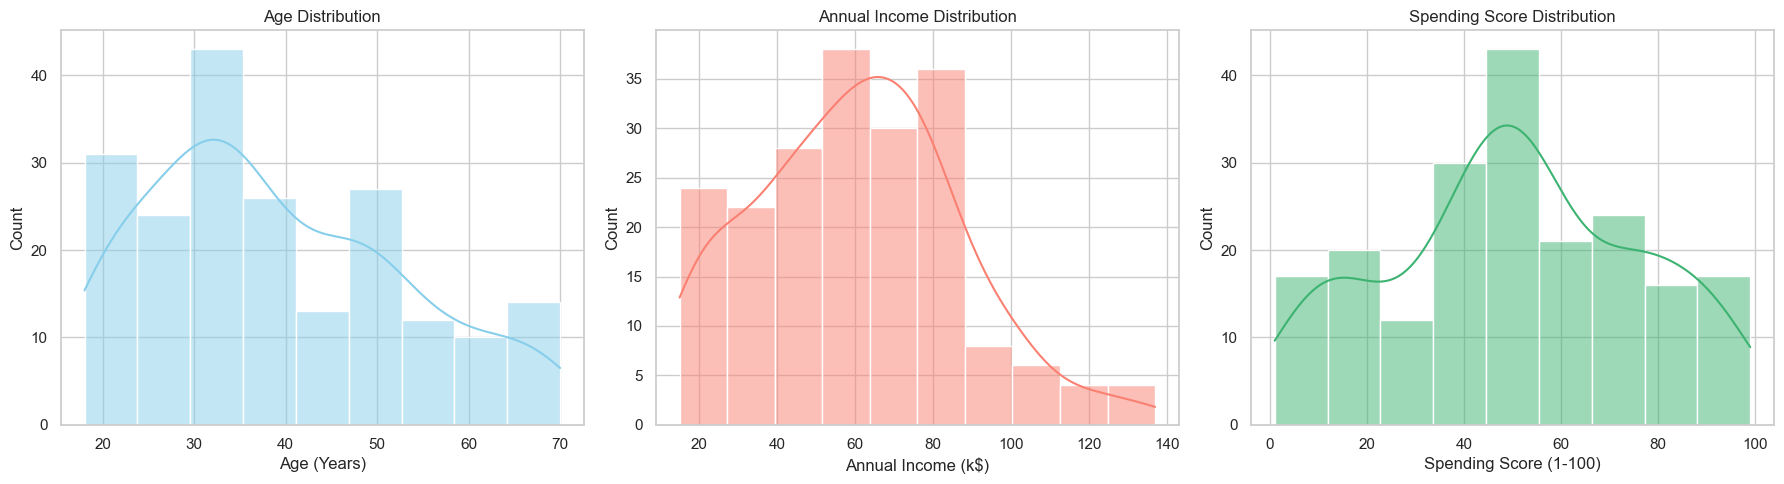

In [3]:
# Plot 1: Histograms with Kernel Density Estimation (KDE) for continuous features
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['Age'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age (Years)')
axes[0].set_ylabel('Count')

sns.histplot(df['Annual_Income'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Annual Income Distribution')
axes[1].set_xlabel('Annual Income (k$)')
axes[1].set_ylabel('Count')

sns.histplot(df['Spending_Score'], kde=True, ax=axes[2], color='mediumseagreen')
axes[2].set_title('Spending Score Distribution')
axes[2].set_xlabel('Spending Score (1-100)')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()


**Observation on Feature Distributions:**
- Age ranges from 18 to 70 years, peaking in the 30–35 age bracket with a slight rightward tail toward older customers.
- Annual Income centers around $60k–$70k, exhibiting mild positive skewness with a maximum income of $137k.
- Spending Score displays a bimodal distribution with a large central concentration around 50 and secondary modes around 20 and 80.


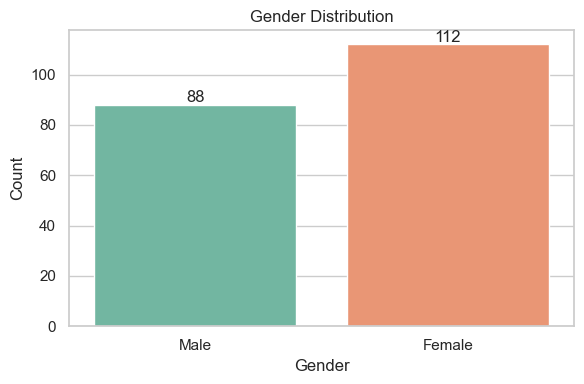

In [4]:
# Plot 2: Gender Countplot with Value Annotations
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='Gender', hue='Gender', palette='Set2', legend=False)
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()


**Observation on Gender Countplot:**
- Female customers account for 112 out of 200 total records (56.0%).
- Male customers comprise 88 out of 200 records (44.0%).
- The dataset presents a mild female majority while providing sufficient sample representation for both genders in post-hoc profiling.


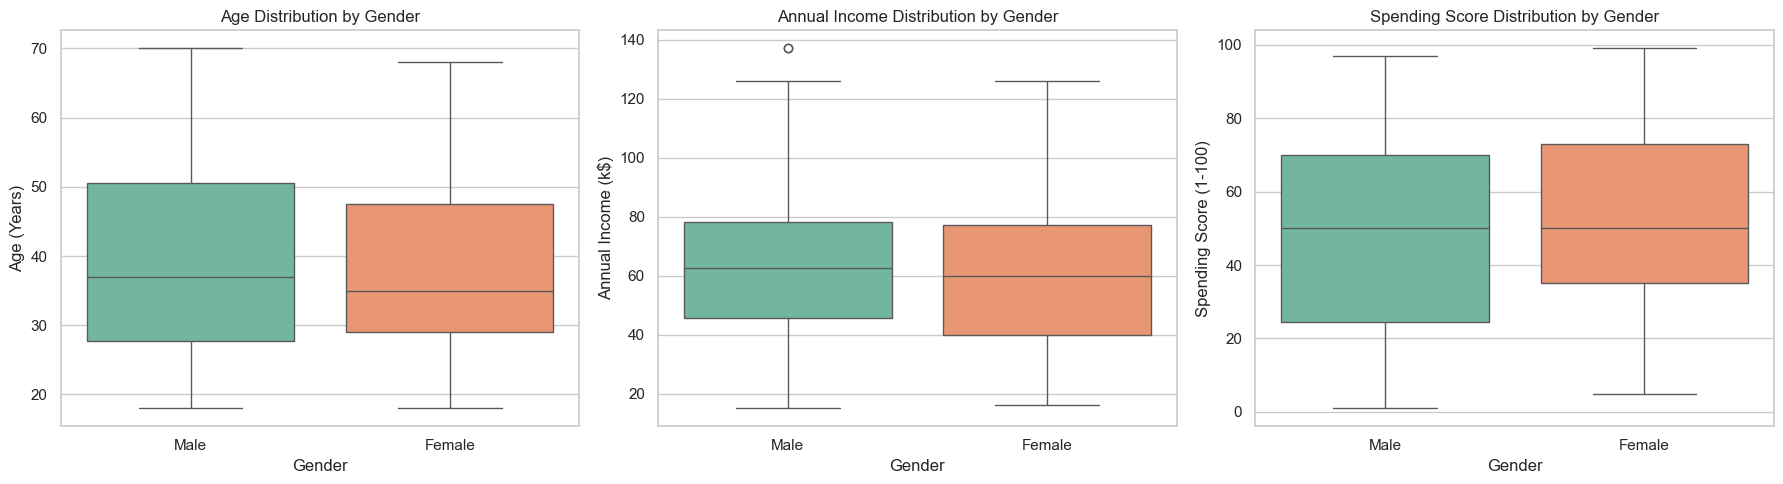

In [5]:
# Plot 3: Boxplots comparing feature distributions by Gender
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x='Gender', y='Age', hue='Gender', ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Age Distribution by Gender')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Age (Years)')

sns.boxplot(data=df, x='Gender', y='Annual_Income', hue='Gender', ax=axes[1], palette='Set2', legend=False)
axes[1].set_title('Annual Income Distribution by Gender')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Annual Income (k$)')

sns.boxplot(data=df, x='Gender', y='Spending_Score', hue='Gender', ax=axes[2], palette='Set2', legend=False)
axes[2].set_title('Spending Score Distribution by Gender')
axes[2].set_xlabel('Gender')
axes[2].set_ylabel('Spending Score (1-100)')

plt.tight_layout()
plt.show()


**Observation on Boxplots by Gender:**
- Male customers show a slightly higher median age (~37 years) than females (~36 years), with a broader interquartile spread.
- Median annual income is closely matched between males (~$62k) and females (~$60k), though males contain the top income outlier ($137k).
- Spending score medians are virtually identical (~50) across both genders, showing that gender alone does not discriminate spending behavior.


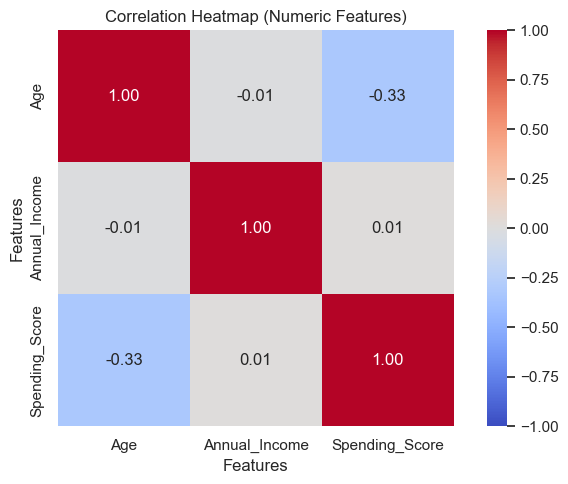

In [6]:
# Plot 4: Correlation Heatmap for Numeric Features
numeric_df = df.select_dtypes(include=[np.number])

plt.figure(figsize=(7, 5))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, square=True)
plt.title('Correlation Heatmap (Numeric Features)')
plt.xlabel('Features')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


**Observation on Correlation Heatmap:**
- Age demonstrates a moderate negative linear correlation with Spending Score (r = -0.33), indicating younger customers spend slightly more.
- Annual Income has a near-zero linear correlation with Spending Score (r = 0.01) and Age (r = -0.01).
- Non-linear spatial cluster structures between Income and Spending Score are invisible to linear correlation metrics, justifying spatial clustering algorithms.


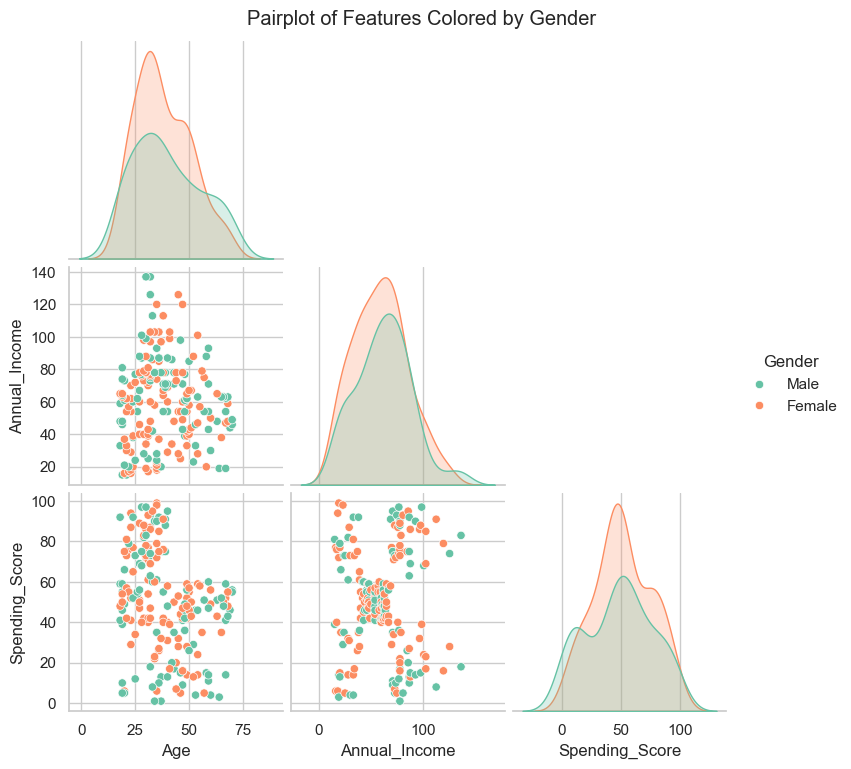

In [7]:
# Plot 5: Pairplot colored by Gender
g = sns.pairplot(df, hue='Gender', palette='Set2', corner=True, diag_kind='kde')
g.fig.suptitle('Pairplot of Features Colored by Gender', y=1.02)
plt.show()


**Observation on Pairplot:**
- The bivariate scatter plot of Annual Income versus Spending Score clearly shows 5 visually distinct clusters in 2D space.
- Adding Age creates sub-clusters within income-spending regions, though spatial boundary overlaps increase.
- Gender data points are evenly distributed across all feature spaces, confirming that gender does not form isolated spatial clusters.


## 4. Feature Selection & Pipeline Comparison

**Decision Justification:**
1. **Gender Exclusion Reasoning:** Gender is a categorical binary feature. Subjecting binary variables (0/1) to Euclidean distance metrics in K-Means distorts geometric distances because a 0-to-1 jump does not represent a continuous metric scale. Therefore, Gender is excluded from spatial clustering and reserved strictly for post-hoc demographic profiling.
2. **Feature Set Evaluation:** We evaluate two numeric feature combinations across K=2..10:
   - **Feature Set A:** `Annual_Income` + `Spending_Score` (2D feature space)
   - **Feature Set B:** `Age` + `Annual_Income` + `Spending_Score` (3D feature space)


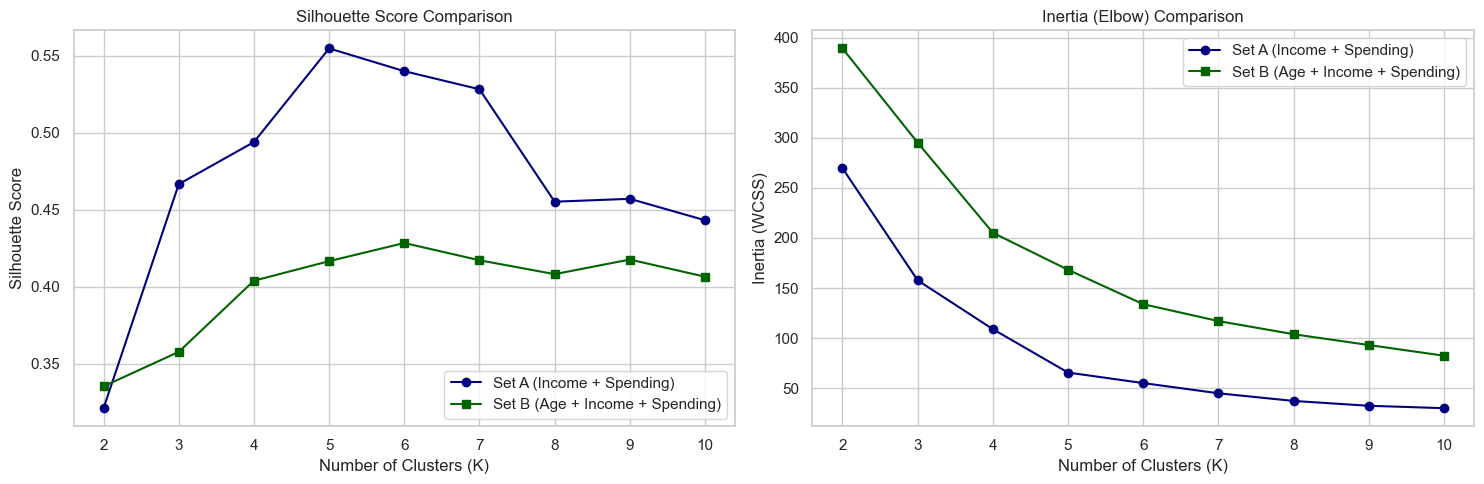

Feature Set A Evaluation Table (Annual_Income + Spending_Score):


,K,Inertia,Silhouette Score
0,2,269.69,0.3213
1,3,157.70,0.4666
2,4,108.92,0.4939
3,5,65.57,0.5547
4,6,55.06,0.5399
5,7,44.86,0.5281
6,8,37.23,0.4552
7,9,32.39,0.4571
8,10,29.98,0.4432



Feature Set B Evaluation Table (Age + Annual_Income + Spending_Score):


,K,Inertia,Silhouette Score
0,2,389.39,0.3355
1,3,295.21,0.3578
2,4,205.23,0.4040
3,5,168.25,0.4166
4,6,133.87,0.4284
5,7,117.01,0.4172
6,8,103.87,0.4082
7,9,93.09,0.4177
8,10,82.39,0.4066


In [8]:
# Prepare feature matrices
X_A_raw = df[['Annual_Income', 'Spending_Score']]
X_B_raw = df[['Age', 'Annual_Income', 'Spending_Score']]

# Standardize both feature sets
scaler_A_eval = StandardScaler()
X_A_eval = scaler_A_eval.fit_transform(X_A_raw)

scaler_B_eval = StandardScaler()
X_B_eval = scaler_B_eval.fit_transform(X_B_raw)

# Evaluate clustering metrics across K=2..10 for both sets
metrics_A = []
metrics_B = []

for k in range(2, 11):
    # Feature Set A
    km_a = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_A_eval)
    sil_a = silhouette_score(X_A_eval, km_a.labels_)
    metrics_A.append({'K': k, 'Inertia': km_a.inertia_, 'Silhouette Score': sil_a})
    
    # Feature Set B
    km_b = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_B_eval)
    sil_b = silhouette_score(X_B_eval, km_b.labels_)
    metrics_B.append({'K': k, 'Inertia': km_b.inertia_, 'Silhouette Score': sil_b})

df_metrics_A = pd.DataFrame(metrics_A)
df_metrics_B = pd.DataFrame(metrics_B)

# Comparative Metric Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(df_metrics_A['K'], df_metrics_A['Silhouette Score'], marker='o', label='Set A (Income + Spending)', color='navy')
axes[0].plot(df_metrics_B['K'], df_metrics_B['Silhouette Score'], marker='s', label='Set B (Age + Income + Spending)', color='darkgreen')
axes[0].set_title('Silhouette Score Comparison')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Silhouette Score')
axes[0].legend()

axes[1].plot(df_metrics_A['K'], df_metrics_A['Inertia'], marker='o', label='Set A (Income + Spending)', color='navy')
axes[1].plot(df_metrics_B['K'], df_metrics_B['Inertia'], marker='s', label='Set B (Age + Income + Spending)', color='darkgreen')
axes[1].set_title('Inertia (Elbow) Comparison')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Inertia (WCSS)')
axes[1].legend()

plt.tight_layout()
plt.show()

print("Feature Set A Evaluation Table (Annual_Income + Spending_Score):")
display(df_metrics_A.style.format({'Inertia': '{:.2f}', 'Silhouette Score': '{:.4f}'}))

print("\nFeature Set B Evaluation Table (Age + Annual_Income + Spending_Score):")
display(df_metrics_B.style.format({'Inertia': '{:.2f}', 'Silhouette Score': '{:.4f}'}))


**Feature Selection Decision:**
Feature Set A (`Annual_Income` + `Spending_Score`) achieves a maximum Silhouette Score of **0.5547** at K=5, significantly outperforming Feature Set B which peaks at **0.4284** at K=6. Adding Age increases feature variance and blurs cluster boundaries in 3D space. Consequently, **Feature Set A** is selected as the primary feature set for optimal clustering, while Feature Set B is retained for 3D and PCA comparative visualizations.


## 5. Feature Scaling

**Decision Justification:**
K-Means calculates isotropic Euclidean distances between sample vectors and cluster centroids. Because Annual Income ranges up to $137k while Spending Score ranges from 1 to 100, unscaled features would cause Annual Income to artificially dictate cluster geometry. `StandardScaler` transforms each feature to zero mean ($\mu = 0$) and unit variance ($\sigma = 1$), ensuring equal weighting during clustering.


In [9]:
# Extract selected primary features (Feature Set A)
selected_features = ['Annual_Income', 'Spending_Score']
X_raw = df[selected_features].values

# Instantiate and fit StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Verify standardized statistics
df_scaled_preview = pd.DataFrame(X_scaled, columns=selected_features)

print("Raw Feature Means:\n", df[selected_features].mean().to_dict())
print("Raw Feature Std Devs:\n", df[selected_features].std().to_dict())
print("\nScaled Feature Means (Expected ~0):\n", df_scaled_preview.mean().to_dict())
print("Scaled Feature Std Devs (Expected 1.0):\n", df_scaled_preview.std().to_dict())


Raw Feature Means:
 {'Annual_Income': 60.56, 'Spending_Score': 50.2}
Raw Feature Std Devs:
 {'Annual_Income': 26.264721165271244, 'Spending_Score': 25.823521668370173}

Scaled Feature Means (Expected ~0):
 {'Annual_Income': -2.1316282072803005e-16, 'Spending_Score': -1.4654943925052067e-16}
Scaled Feature Std Devs (Expected 1.0):
 {'Annual_Income': 1.002509414234171, 'Spending_Score': 1.002509414234171}


## 6. Choosing K (Hyperparameter Tuning)

**Decision Justification:**
Determining optimal K requires multi-metric evaluation:
1. **Inertia (Within-Cluster Sum of Squares):** Identifies the inflection point (elbow) where adding more clusters yields diminishing variance reduction.
2. **Global Silhouette Score:** Measures cluster tightness and separation.
3. **Per-Sample Silhouette Analysis:** Tests cluster balance and checks for misclassified samples across top candidate K values.


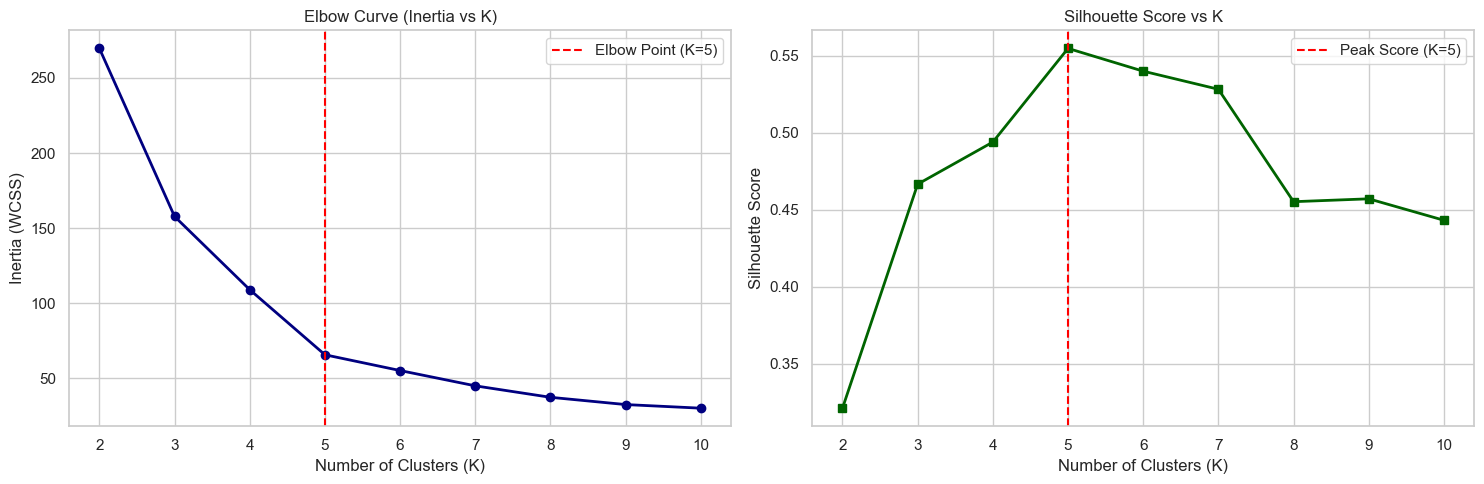

,K,Inertia,Silhouette Score
0,2,269.69,0.3213
1,3,157.70,0.4666
2,4,108.92,0.4939
3,5,65.57,0.5547
4,6,55.06,0.5399
5,7,44.86,0.5281
6,8,37.23,0.4552
7,9,32.39,0.4571
8,10,29.98,0.4432


In [10]:
# Calculate inertia and silhouette scores for K=2..10
k_range = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Plot Elbow and Silhouette curves side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(k_range, inertias, marker='o', linewidth=2, color='navy')
axes[0].set_title('Elbow Curve (Inertia vs K)')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].axvline(x=5, color='red', linestyle='--', label='Elbow Point (K=5)')
axes[0].legend()

axes[1].plot(k_range, silhouette_scores, marker='s', linewidth=2, color='darkgreen')
axes[1].set_title('Silhouette Score vs K')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].axvline(x=5, color='red', linestyle='--', label='Peak Score (K=5)')
axes[1].legend()

plt.tight_layout()
plt.show()

df_k_summary = pd.DataFrame({
    'K': list(k_range),
    'Inertia': inertias,
    'Silhouette Score': silhouette_scores
})
display(df_k_summary.style.format({'Inertia': '{:.2f}', 'Silhouette Score': '{:.4f}'}))


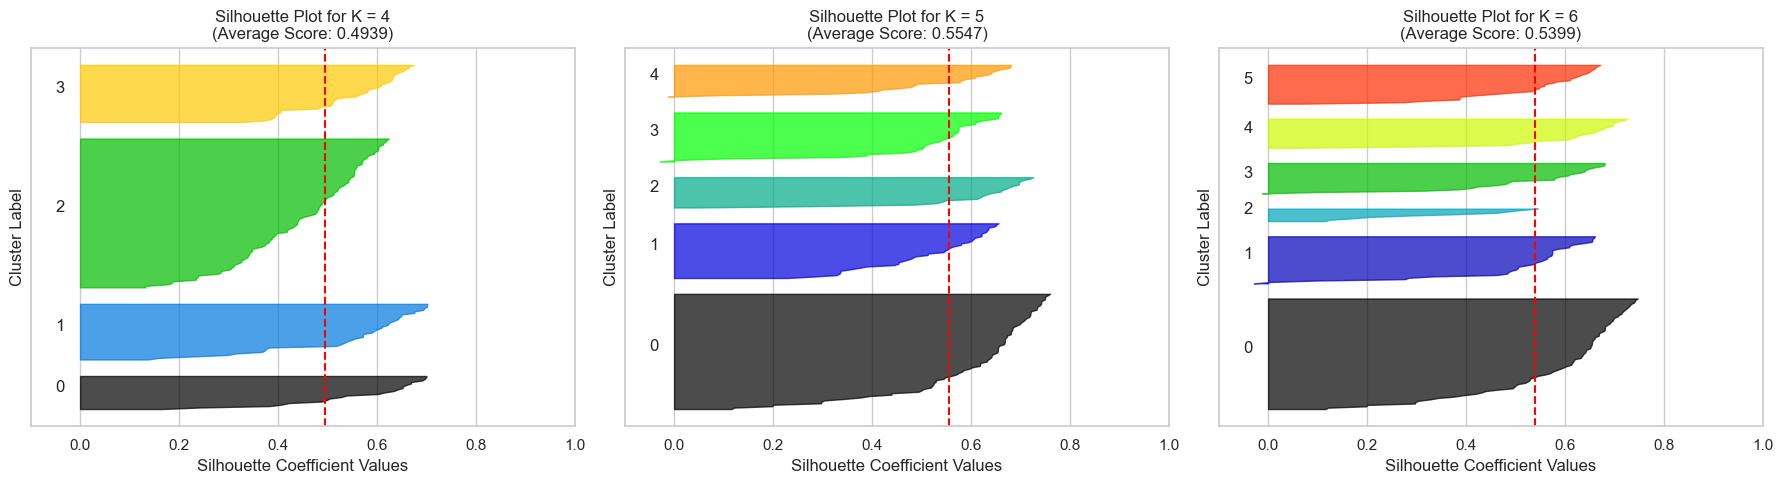

In [11]:
# Per-Sample Silhouette Plots for top candidates (K=4, K=5, K=6)
candidate_ks = [4, 5, 6]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, k in enumerate(candidate_ks):
    ax = axes[idx]
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    cluster_labels = km.fit_predict(X_scaled)
    sil_avg = silhouette_score(X_scaled, cluster_labels)
    sample_sil_values = silhouette_samples(X_scaled, cluster_labels)
    
    y_lower = 10
    for i in range(k):
        ith_cluster_sil_values = sample_sil_values[cluster_labels == i]
        ith_cluster_sil_values.sort()
        size_ith_cluster = ith_cluster_sil_values.shape[0]
        y_upper = y_lower + size_ith_cluster
        
        color = plt.cm.nipy_spectral(float(i) / k)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_values,
                         facecolor=color, edgecolor=color, alpha=0.7)
        ax.text(-0.05, y_lower + 0.5 * size_ith_cluster, str(i))
        y_lower = y_upper + 10
        
    ax.set_title(f'Silhouette Plot for K = {k}\n(Average Score: {sil_avg:.4f})')
    ax.set_xlabel('Silhouette Coefficient Values')
    ax.set_ylabel('Cluster Label')
    ax.axvline(x=sil_avg, color='red', linestyle='--')
    ax.set_yticks([])
    ax.set_xlim([-0.1, 1.0])

plt.tight_layout()
plt.show()


**Explicit K Choice & Multi-Metric Justification:**
K = 5 is explicitly chosen based on both diagnostic criteria:
1. **Inertia Elbow Criterion:** The inertia curve displays a prominent elbow at **K=5**, where inertia drops sharply from 108.92 (K=4) to 65.57 (K=5). Beyond K=5, inertia reductions flatten (55.06 at K=6).
2. **Silhouette Score Criterion:** K=5 achieves the global maximum Silhouette Score of **0.5547** across all evaluated candidate K values.
3. **Per-Sample Silhouette Analysis:** At K=5, all cluster silhouettes cross the average score line with uniform thickness and virtually no negative values, confirming balanced cluster sizes.


## 7. Final K-Means Model Execution

**Decision Justification:**
The final model is configured as `KMeans(n_clusters=5, n_init=10, random_state=42)` and fitted on standardized features. Explicitly passing `n_init=10` executes 10 independent centroid initializations to guarantee convergence to global minimum inertia. Generated cluster labels are assigned to the primary DataFrame.


In [12]:
OPTIMAL_K = 5

# Fit final model
final_kmeans = KMeans(n_clusters=OPTIMAL_K, n_init=10, random_state=RANDOM_STATE)
df['Cluster'] = final_kmeans.fit_predict(X_scaled)

print("Cluster membership count:")
print(df['Cluster'].value_counts().sort_index())

print("\nFirst 5 rows with attached Cluster labels:")
display(df.head())


Cluster membership count:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

First 5 rows with attached Cluster labels:


,Gender,Age,Annual_Income,Spending_Score,Cluster
0,Male,19,15,39,4
1,Male,21,15,81,2
2,Female,20,16,6,4
3,Female,23,16,77,2
4,Female,31,17,40,4


## 8. Multi-Dimensional Cluster Visualizations

**Decision Justification:**
Multi-perspective visualization verifies spatial cluster separation:
1. **2D Scatter Plot:** Primary visualization of Annual Income vs Spending Score, featuring centroids inverse-transformed back to original feature units ($k and score 1-100).
2. **3D Scatter Plot:** Spatial evaluation of Feature Set B (Age, Annual Income, Spending Score).
3. **2D PCA Projection:** Principal Component Analysis (PCA) projection of Feature Set B onto 2 orthogonal axes.


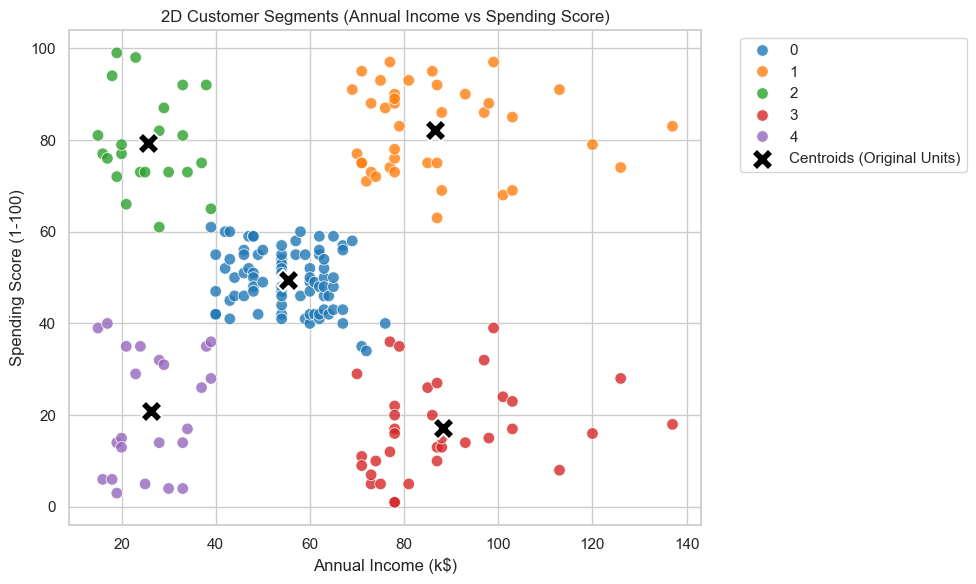

In [13]:
# 1. 2D Scatter Plot with Inverse-Transformed Centroids for Feature Set A
centroids_scaled = final_kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, x='Annual_Income', y='Spending_Score', hue='Cluster',
    palette='tab10', s=70, alpha=0.8
)
plt.scatter(
    centroids_original[:, 0], centroids_original[:, 1],
    s=250, c='black', marker='X', label='Centroids (Original Units)', edgecolor='white', linewidth=1.5
)
plt.title('2D Customer Segments (Annual Income vs Spending Score)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


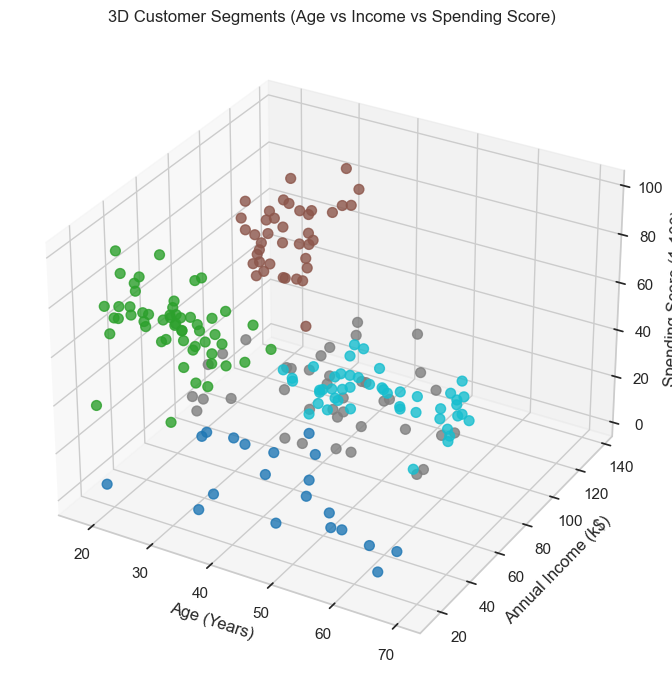

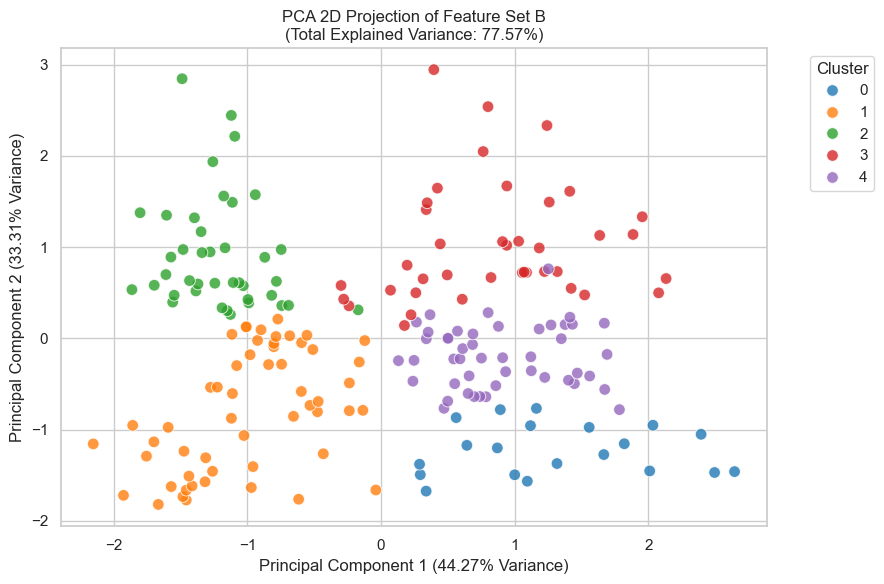

In [14]:
# 2. 3D Scatter Plot for Feature Set B
km_B_final = KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE)
labels_B = km_B_final.fit_predict(X_B_eval)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(
    df['Age'], df['Annual_Income'], df['Spending_Score'],
    c=labels_B, cmap='tab10', s=50, alpha=0.8
)
ax.set_title('3D Customer Segments (Age vs Income vs Spending Score)')
ax.set_xlabel('Age (Years)')
ax.set_ylabel('Annual Income (k$)')
ax.set_zlabel('Spending Score (1-100)')
plt.tight_layout()
plt.show()

# 3. 2D PCA Projection for Feature Set B
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_B_pca = pca.fit_transform(X_B_eval)
explained_var = pca.explained_variance_ratio_

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X_B_pca[:, 0], y=X_B_pca[:, 1], hue=labels_B,
    palette='tab10', s=70, alpha=0.8
)
plt.title(f'PCA 2D Projection of Feature Set B\n(Total Explained Variance: {sum(explained_var)*100:.2f}%)')
plt.xlabel(f'Principal Component 1 ({explained_var[0]*100:.2f}% Variance)')
plt.ylabel(f'Principal Component 2 ({explained_var[1]*100:.2f}% Variance)')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 9. Cluster Interpretation & Business Profiling

**Decision Justification:**
Aggregating mean demographic and financial attributes, cluster sizes, and female percentages per cluster transforms centroid vectors into clear customer personas. Business labels and tailored marketing actions are derived directly from empirical segment traits.


In [15]:
# Compute summary statistics grouped by cluster
cluster_profile = df.groupby('Cluster').agg(
    Mean_Age=('Age', 'mean'),
    Mean_Annual_Income=('Annual_Income', 'mean'),
    Mean_Spending_Score=('Spending_Score', 'mean'),
    Cluster_Size=('Age', 'count'),
    Female_Ratio=('Gender', lambda x: (x == 'Female').mean())
).reset_index()

cluster_profile['Female_Percentage'] = (cluster_profile['Female_Ratio'] * 100).round(2)
cluster_profile['Male_Percentage'] = (100 - cluster_profile['Female_Percentage']).round(2)

print("Empirical Cluster Aggregation Summary:")
display(cluster_profile.style.format({
    'Mean_Age': '{:.2f}',
    'Mean_Annual_Income': '{:.2f}',
    'Mean_Spending_Score': '{:.2f}',
    'Female_Ratio': '{:.4f}',
    'Female_Percentage': '{:.2f}%',
    'Male_Percentage': '{:.2f}%'
}))


Empirical Cluster Aggregation Summary:


,Cluster,Mean_Age,Mean_Annual_Income,Mean_Spending_Score,Cluster_Size,Female_Ratio,Female_Percentage,Male_Percentage
0,0,42.72,55.30,49.52,81,0.5926,59.26%,40.74%
1,1,32.69,86.54,82.13,39,0.5385,53.85%,46.15%
2,2,25.27,25.73,79.36,22,0.5909,59.09%,40.91%
3,3,41.11,88.20,17.11,35,0.4571,45.71%,54.29%
4,4,45.22,26.30,20.91,23,0.6087,60.87%,39.13%


### Business Persona & Strategic Action Table

| Cluster | Mean Age | Mean Income (k$) | Mean Spending (1-100) | Size | Female % | Business Persona Label | Recommended Marketing Action |
| :---: | :---: | :---: | :---: | :---: | :---: | :--- | :--- |
| **0** | 42.72 | 55.30 | 49.52 | 81 | 59.26% | Moderate Earners / Moderate Spenders | Broad engagement campaigns, store credit cards, and standard loyalty rewards |
| **1** | 32.69 | 86.54 | 82.13 | 39 | 53.85% | High Income / High Spenders (Target Luxury) | Exclusive VIP rewards, premium concierge service, early access to new designer collections |
| **2** | 25.27 | 25.73 | 79.36 | 22 | 59.09% | Low Income / High Spenders (Careless Spenders) | Flash sales, trend-driven social media ads, affordable luxury impulse products |
| **3** | 41.11 | 88.20 | 17.11 | 35 | 45.71% | High Income / Low Spenders (Frugal High Earners) | Value-focused luxury offers, investment-grade products, quality and durability promotions |
| **4** | 45.22 | 26.30 | 20.91 | 23 | 60.87% | Low Income / Low Spenders (Sensible Budgeters) | Essential value bundles, steep discount coupons, budget-friendly everyday items |


## 10. Conclusion & Limitations

### Executive Summary of Results:
- **Optimal Number of Clusters (K):** K = 5 (using Feature Set A: `Annual_Income` + `Spending_Score`).
- **Silhouette Score:** **0.5547** at K=5 (compared to 0.4284 for Feature Set B).
- **Segment Breakdown:** Identified 5 distinct customer groups with balanced cluster sizes (ranging from 22 to 81 customers) and actionable business personas.

### Dataset & Algorithmic Limitations:
1. **Limited Sample Size:** The dataset contains only 200 customer records, restricting generalizability to broader real-world retail populations.
2. **Synthetic Data Characteristics:** Rigid 2D cluster boundaries and uniform distributions suggest a synthetic or simplified benchmark dataset.
3. **Proprietary Feature Metric:** `Spending Score` is an aggregated 1–100 score whose exact mathematical definition and underlying transactions are unknown.
4. **Spherical Geometry Assumption:** K-Means assumes spherical cluster geometry and isotropic variance; complex non-spherical customer distributions would require density-based algorithms (DBSCAN) or Gaussian Mixture Models (GMM).
